# Notebook 10 — Revenue Exposure and Retention Planning

**Research project:** Customer Segmentation and Retention Analysis Using Machine Learning and Statistical Modelling<br>
**Forecast cutoff:** September 10, 2010 · **TEST cohort:** 3,373 customers<br>
**Currency:** GBP · **Models:** existing saved Purchase Clock and spending forecasts

> Historical research demonstration. It is not a current-business forecast, treatment-effect estimate, promise of recovered revenue, or individual guarantee.

## 01. Research objective and predeclared financial definitions

This notebook separates five different quantities:

1. **Current expected revenue:** saved purchase probability multiplied by saved
   conditional expected spending.
2. **Model disagreement:** differences between the personalized, historical-rate,
   and segment-aware forecasts. Alternative models are not counterfactuals.
3. **Revenue exposure:** a positive shortfall from a documented, same-customer,
   same-cutoff, same-horizon business reference. No eligible reference exists in
   the saved artifacts, so exposure is **not estimable**, not zero.
4. **Nonreturn-spending proxy:** `(1 − purchase probability) × conditional
   expected spending`. This is a screening proxy, not observed loss or
   recoverable revenue.
5. **Campaign scenarios:** explicitly hypothetical response and uplift inputs.
   No randomized intervention outcomes exist, so causal lift is not estimable.

The saved Purchase Clock and spending models are loaded without retraining or
modifying their artifacts. Future outcomes are kept separate from ranking
features and joined only after candidate rankings are frozen for evaluation.

In [1]:
import sys
from pathlib import Path

candidate_roots = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next(
    root for root in candidate_roots
    if (root / "src" / "retention_research.py").is_file()
    and (root / "models" / "purchase_clock").is_dir()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src.retention_planner import (
    RANKING_STRATEGIES,
    RetentionScenario,
    allocate_contact_budget,
    rank_retention_candidates,
    simulate_retention_scenario,
)
from src.retention_research import (
    profile_warm_revenue_api,
    run_revenue_exposure_analysis,
)

analysis = run_revenue_exposure_analysis(PROJECT_ROOT)
evaluation = analysis["evaluation"]
scenario_sensitivity = analysis["scenario_sensitivity"]
profiling = analysis["profiling"]

print("Project root:", PROJECT_ROOT)
print("TEST cutoff:", evaluation["metadata"]["forecast_cutoff"])
print("TEST customers:", evaluation["metadata"]["evaluation_customer_count"])
print("Saved Purchase Clock:", evaluation["metadata"]["purchase_clock_model_version"])
print("Saved spending model:", evaluation["metadata"]["spending_model_version"])
model_metadata = json.loads(
    (PROJECT_ROOT / "models" / "revenue_exposure" / "metadata.json")
    .read_text(encoding="utf-8")
)
print("Research metadata only; no fitted model created:",
      model_metadata["fitted_model_created"] is False)

Project root: /home/runner/workspace/.local/worktrees/notebook10
TEST cutoff: 2010-09-10
TEST customers: 3373
Saved Purchase Clock: purchase-clock-v2
Saved spending model: spending-forecast-v2
Research metadata only; no fitted model created: True


## 02. Current expected revenue, disagreements, and exposure status

The summary below reports portfolio totals from the saved forecasts. A model
difference is shown as a disagreement, not as a shortfall. Since a defensible
matched reference forecast is unavailable, the reference-based exposure field
must remain null.

In [2]:
portfolio = pd.DataFrame([
    {"horizon_days": int(horizon), **summary}
    for horizon, summary in evaluation["portfolio_by_horizon"].items()
])
display(
    portfolio[
        [
            "horizon_days",
            "eligible_customers",
            "personalized_expected_revenue_total_gbp",
            "historical_rate_forecast_total_gbp",
            "segment_forecast_total_gbp",
            "estimated_revenue_exposure_total_gbp",
            "exposure_status",
            "opportunity_proxy_total_gbp",
        ]
    ].round(2)
)
display(pd.DataFrame(evaluation["forecast_disagreements"]).T)

assert portfolio["exposure_status"].eq("not_estimable").all()
assert portfolio["estimated_revenue_exposure_total_gbp"].isna().all()
assert evaluation["financial_definitions"]["causal_effect"] is None

,horizon_days,eligible_customers,personalized_expected_revenue_total_gbp,historical_rate_forecast_total_gbp,segment_forecast_total_gbp,estimated_revenue_exposure_total_gbp,exposure_status,opportunity_proxy_total_gbp
0,30,3373,639659.40,858475.87,752723.56,None,not_estimable,904417.94
1,60,3373,1257116.38,1763483.07,1458412.19,None,not_estimable,780672.95
2,90,3373,1861869.51,2942543.56,2823576.74,None,not_estimable,598292.99


,historical_minus_personalized_forecast_difference_gbp,segment_minus_personalized_forecast_difference_gbp
30,2.188165e+05,113064.168328
60,5.063667e+05,201295.816342
90,1.080674e+06,961707.226244


## 03. Customer and portfolio concentration

Historical gross spending is an observed historical quantity; personalized
expected revenue is a model output; the nonreturn proxy is a screening signal.
The top-customer shares below are descriptive concentrations only.

metric,historical_gross_spending_gbp,nonreturn_weighted_conditional_spending_proxy_gbp,personalized_expected_revenue_gbp
horizon_days,,,
30,0.596,0.25,0.452
60,0.596,0.26,0.470
90,0.596,0.23,0.527


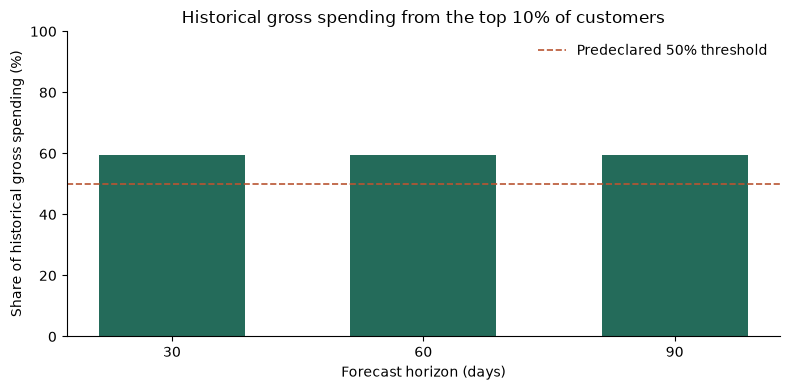

In [3]:
concentration = pd.DataFrame(evaluation["concentration"])
top_ten = concentration.loc[concentration["top_customer_share"].eq(0.10)]
display(
    top_ten.pivot(
        index="horizon_days",
        columns="metric",
        values="portfolio_share",
    ).round(3)
)

historical = top_ten.loc[
    top_ten["metric"].eq("historical_gross_spending_gbp")
].sort_values("horizon_days")
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(historical["horizon_days"].astype(str), historical["portfolio_share"] * 100,
       color="#246B5A", width=0.58)
ax.axhline(50, color="#B95532", linestyle="--", linewidth=1.2,
           label="Predeclared 50% threshold")
ax.set(title="Historical gross spending from the top 10% of customers",
       xlabel="Forecast horizon (days)", ylabel="Share of historical gross spending (%)")
ax.set_ylim(0, 100)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 04. Retention-ranking comparisons

Six deterministic screening strategies are compared at the top 1%, 5%, 10%,
and 20% budgets. For 30 and 60 days, one strategy is selected using prospective
validation outcomes among customers above the horizon-specific TRAIN 75th
percentile of historical gross spending. That rule is then frozen and assessed
on the September 10 TEST cohort. The 90-day cutoff has no prospective saved
vintage and is therefore descriptive only.

The target is the observed future nonpurchase rate—not recovered revenue or
campaign effectiveness. TEST outcomes do not choose the policy.

In [4]:
validation_selected = evaluation["validation_selected_strategy_evaluation"]
for horizon, result in validation_selected.items():
    print(f"{horizon}-day:", json.dumps(result, indent=2))

comparison_rows = []
for horizon, comparison in evaluation["ranking_selection_and_test_evaluation"].items():
    for item in comparison["test_historically_valuable_baseline_comparisons"]:
        comparison_rows.append({
            "horizon_days": int(horizon),
            "budget_fraction": item["budget_fraction"],
            "strategy": item["ranking_strategy"],
            "selected_customers": item["selected_customers"],
            "historically_valuable_future_nonpurchase_rate":
                item["future_nonpurchase_rate"],
            "selected_on_validation":
                item["ranking_strategy"] == comparison["selected_strategy_from_validation"],
        })
ranking_test = pd.DataFrame(comparison_rows)
display(ranking_test.pivot(
    index=["strategy", "budget_fraction"],
    columns="horizon_days",
    values="historically_valuable_future_nonpurchase_rate",
).round(3))
display(pd.DataFrame(evaluation["ranking_method_comparisons"]["30"]["comparisons"]).head(12))

assert evaluation["metadata"]["test_outcomes_used_for_selection"] is False
assert evaluation["ranking_selection_and_test_evaluation"]["90"][
    "selected_strategy_from_validation"
] is None

30-day: {
  "selected_on_validation": "nonreturn_probability",
  "validation_high_value_nonpurchase_rate": 0.8736842105263158,
  "test_high_value_nonpurchase_rate": 0.6886792452830188,
  "test_high_value_baseline_rates": {
    "historical_gross_spending": 0.3018867924528302,
    "recency_only": 0.8113207547169812,
    "nonreturn_probability": 0.6886792452830188,
    "conditional_expected_spending": 0.5660377358490566,
    "nonreturn_spending_proxy": 0.7641509433962265,
    "pareto_risk_value": 0.5849056603773585
  },
  "improved_on_all_test_baselines": false,
  "test_outcomes_used_for_selection": false,
  "test_selected_cohort_bootstrap_95": {
    "status": "estimated",
    "customer_count": 106,
    "metric": "future_nonpurchase_rate",
    "estimate": 0.6886792452830188,
    "lower": 0.5988207547169812,
    "upper": 0.7735849056603774,
    "confidence_level": 0.95,
    "method": "customer-level percentile bootstrap of a fixed selected cohort",
    "resamples": 500,
    "seed": 2026115

horizon_days                                      30     60     90
strategy                      budget_fraction                     
conditional_expected_spending 0.01             0.091  0.000  0.000
                              0.05             0.491  0.211  0.061
                              0.10             0.566  0.239  0.136
                              0.20             0.542  0.265  0.155
historical_gross_spending     0.01             0.091  0.000  0.071
                              0.05             0.226  0.088  0.121
                              0.10             0.302  0.150  0.144
                              0.20             0.373  0.190  0.155
nonreturn_probability         0.01             0.545  0.667  0.714
                              0.05             0.717  0.632  0.576
                              0.10             0.689  0.513  0.439
                              0.20             0.693  0.513  0.413
nonreturn_spending_proxy      0.01             0.909  0.833  0.786
                              0.05             0.811  0.684  0.576
                              0.10             0.764  0.593  0.538
                              0.20             0.726  0.558  0.428
pareto_risk_value             0.01             0.545  0.417  0.500
                              0.05             0.604  0.474  0.394
                              0.10             0.585  0.425  0.364
                              0.20             0.656  0.398  0.322
recency_only                  0.01             0.818  0.667  0.500
                              0.05             0.906  0.702  0.545
                              0.10             0.811  0.637  0.515
                              0.20             0.670  0.491  0.405

,budget_fraction,eligible_customers,selected_customers,future_nonpurchase_rate,future_purchase_rate,nonpurchase_capture_rate,observable_nonpurchase_count,status,ranking_strategy
0,0.01,3373,34,0.176471,0.823529,0.002468,6,evaluated,historical_gross_spending
1,0.05,3373,169,0.319527,0.680473,0.022213,54,evaluated,historical_gross_spending
2,0.10,3373,338,0.405325,0.594675,0.056355,137,evaluated,historical_gross_spending
3,0.20,3373,675,0.471111,0.528889,0.130810,318,evaluated,historical_gross_spending
4,0.01,3373,34,0.882353,0.117647,0.012341,30,evaluated,recency_only
5,0.05,3373,169,0.899408,0.100592,0.062526,152,evaluated,recency_only
6,0.10,3373,338,0.884615,0.115385,0.122995,299,evaluated,recency_only
7,0.20,3373,675,0.863704,0.136296,0.239819,583,evaluated,recency_only
8,0.01,3373,34,0.970588,0.029412,0.013575,33,evaluated,nonreturn_probability
9,0.05,3373,169,0.934911,0.065089,0.064994,158,evaluated,nonreturn_probability


## 05. Ranking overlap and evidence limits

Low overlap means methods surface different customers; it does not establish
which group will respond to outreach. Bootstrap intervals below describe
nonpurchase-rate uncertainty within the fixed validation-selected TEST
selection. They do not include model-selection uncertainty or campaign uplift.

In [5]:
for horizon in ("30", "60"):
    rows = evaluation["ranking_method_comparisons"][horizon][
        "selection_overlap_at_10_percent"
    ]
    matrix = pd.DataFrame(rows).pivot(
        index="strategy_a",
        columns="strategy_b",
        values="jaccard_similarity",
    )
    print(f"{horizon}-day top-10% Jaccard overlap")
    display(matrix.round(2))

for horizon in ("30", "60"):
    result = validation_selected[horizon]
    print(
        horizon,
        "days: selected on validation =",
        result["selected_on_validation"],
        "| TEST high-value nonpurchase rate =",
        round(result["test_high_value_nonpurchase_rate"], 3),
        "| 95% fixed-cohort bootstrap =",
        result["test_selected_cohort_bootstrap_95"]["lower"],
        "to",
        result["test_selected_cohort_bootstrap_95"]["upper"],
        "| better than all matched TEST baselines =",
        result["improved_on_all_test_baselines"],
    )

30-day top-10% Jaccard overlap


strategy_b,conditional_expected_spending,historical_gross_spending,nonreturn_probability,nonreturn_spending_proxy,pareto_risk_value,recency_only
strategy_a,,,,,,
conditional_expected_spending,1.00,0.36,0.00,0.34,0.17,0.03
historical_gross_spending,0.36,1.00,0.00,0.07,0.05,0.01
nonreturn_probability,0.00,0.00,1.00,0.00,0.29,0.24
nonreturn_spending_proxy,0.34,0.07,0.00,1.00,0.20,0.09
pareto_risk_value,0.17,0.05,0.29,0.20,1.00,0.43
recency_only,0.03,0.01,0.24,0.09,0.43,1.00


60-day top-10% Jaccard overlap


strategy_b,conditional_expected_spending,historical_gross_spending,nonreturn_probability,nonreturn_spending_proxy,pareto_risk_value,recency_only
strategy_a,,,,,,
conditional_expected_spending,1.00,0.61,0.00,0.17,0.16,0.02
historical_gross_spending,0.61,1.00,0.00,0.06,0.09,0.01
nonreturn_probability,0.00,0.00,1.00,0.01,0.26,0.24
nonreturn_spending_proxy,0.17,0.06,0.01,1.00,0.26,0.09
pareto_risk_value,0.16,0.09,0.26,0.26,1.00,0.29
recency_only,0.02,0.01,0.24,0.09,0.29,1.00


30 days: selected on validation = nonreturn_probability | TEST high-value nonpurchase rate = 0.689 | 95% fixed-cohort bootstrap = 0.5988207547169812 to 0.7735849056603774 | better than all matched TEST baselines = False
60 days: selected on validation = nonreturn_spending_proxy | TEST high-value nonpurchase rate = 0.593 | 95% fixed-cohort bootstrap = 0.504424778761062 to 0.6814159292035398 | better than all matched TEST baselines = False


## 06. Behavior indicators and historical reliability

Notebook 08 indicators are descriptive, optional eligibility filters. Sparse
history is surfaced as a coverage limitation; no numerical reliability
multiplier is applied to customer scores. Notebook 09 subgroup metrics describe
historical groups and do not guarantee an individual forecast.

In [6]:
behavior_support_rows = []
for horizon, forecast in analysis["forecast_tables"].items():
    for history_group, group in forecast.groupby("history_group", dropna=False):
        behavior_support_rows.append({
            "horizon_days": horizon,
            "history_group": history_group,
            "customers": int(len(group)),
            "sufficient_behavior_history":
                int(group["history_sufficiency"].eq("sufficient").sum()),
            "declining_purchase_rate":
                int(pd.to_numeric(group["purchase_rate_ratio"], errors="coerce").lt(1).sum()),
            "historical_reliability_status":
                group["reliability_status"].iloc[0],
            "historical_reliability_group_count":
                int(group["reliability_evidence_count"].iloc[0]),
        })
display(pd.DataFrame(behavior_support_rows))

print("Reliability evidence cutoff:", evaluation["metadata"]["forecast_cutoff"])
print("Reliability evidence is an individual guarantee:",
      analysis["forecast_tables"][30]["reliability_is_individual_guarantee"].any())

,horizon_days,history_group,customers,sufficient_behavior_history,declining_purchase_rate,historical_reliability_status,historical_reliability_group_count
0,30,Exactly one purchase,1281,0,293,well_supported_historical_evaluation_group,1281
1,30,Five or more purchases,726,725,445,well_supported_historical_evaluation_group,726
2,30,Two to four purchases,1366,0,689,well_supported_historical_evaluation_group,1366
3,60,Exactly one purchase,1281,0,293,well_supported_historical_evaluation_group,1281
4,60,Five or more purchases,726,725,445,well_supported_historical_evaluation_group,726
5,60,Two to four purchases,1366,0,689,well_supported_historical_evaluation_group,1366
6,90,Exactly one purchase,1281,0,293,well_supported_historical_evaluation_group,1281
7,90,Five or more purchases,726,725,445,well_supported_historical_evaluation_group,726
8,90,Two to four purchases,1366,0,689,well_supported_historical_evaluation_group,1366


Reliability evidence cutoff: 2010-09-10
Reliability evidence is an individual guarantee: False


## 07. Hypothetical contact-budget scenarios

Each scenario varies a user-defined response probability, purchase uplift if
responded, contact cost, and campaign budget. Benefits use
`Δp = min(1 − p, response × uplift)` and `Δrevenue = Δp × conditional spending`.
No gross margin is assumed unless a user supplies one. The output is a planning
illustration, not a causal estimate or net-profit forecast.

### Illustrative break-even check

When an analyst supplies a gross-margin assumption, the code reports the
hypothetical response or purchase-uplift conditions required to cover contact
costs. Without margin, only revenue and contact cost are reported. These
algebraic thresholds are not observed or recommended campaign rates.

In [7]:
scenario_rows = pd.DataFrame(scenario_sensitivity["scenario_results"])
print("Scenario combinations:", len(scenario_rows))
display(
    scenario_rows.groupby(
        ["horizon_days", "ranking_strategy"], as_index=False
    ).agg(
        median_selected_contacts=("selected_customer_count", "median"),
        median_cost_gbp=("campaign_cost_gbp", "median"),
        median_hypothetical_revenue_gbp=(
            "hypothetical_incremental_revenue_gbp", "median"
        ),
        causal_estimate=("causal_estimate", "max"),
    ).head(18).round(2)
)

stability = [
    row
    for horizon in scenario_sensitivity["scenario_selection_stability"].values()
    for row in horizon["selection_stability"]
]
display(pd.DataFrame(stability).head(12))
assert not scenario_rows["causal_estimate"].any()

demo_scenario = RetentionScenario(
    horizon_days=30,
    campaign_budget_gbp=500,
    contact_cost_gbp=3,
    maximum_contacts=150,
    assumed_response_probability=0.20,
    assumed_purchase_uplift_if_responded=0.05,
    assumed_gross_margin_rate=0.35,
)
demo_ranked = rank_retention_candidates(
    analysis["forecast_tables"][30], "nonreturn_spending_proxy"
)
demo_contacts = allocate_contact_budget(
    demo_ranked, 500, 3, 150
)
demo_result = simulate_retention_scenario(demo_contacts, demo_scenario)
display(pd.DataFrame([{
    "selected_contacts": demo_result["selected_customer_count"],
    "campaign_cost_gbp": demo_result["campaign_cost_gbp"],
    "hypothetical_incremental_revenue_gbp":
        demo_result["hypothetical_incremental_revenue_gbp"],
    "hypothetical_contribution_gbp":
        demo_result["hypothetical_incremental_contribution_gbp"],
}]))
display(pd.DataFrame([demo_result["break_even_information"]]).T)

Scenario combinations: 1458


,horizon_days,ranking_strategy,median_selected_contacts,median_cost_gbp,median_hypothetical_revenue_gbp,causal_estimate
0,30,conditional_expected_spending,166.0,500.0,934.47,False
1,30,historical_gross_spending,166.0,500.0,741.28,False
2,30,nonreturn_probability,166.0,500.0,146.95,False
3,30,nonreturn_spending_proxy,166.0,500.0,790.98,False
4,30,pareto_risk_value,166.0,500.0,501.71,False
5,30,recency_only,166.0,500.0,314.41,False
6,60,conditional_expected_spending,166.0,500.0,1127.28,False
7,60,historical_gross_spending,166.0,500.0,1044.30,False
8,60,nonreturn_probability,166.0,500.0,145.19,False
9,60,nonreturn_spending_proxy,166.0,500.0,873.90,False


,horizon_days,ranking_strategy,selection_order_depends_on_response_or_uplift,same_budget_response_uplift_jaccard_min,same_budget_response_uplift_jaccard_median,comparison_count,interpretation
0,30,historical_gross_spending,False,1.0,1.0,324,Scores are intentionally independent of campai...
1,30,recency_only,False,1.0,1.0,324,Scores are intentionally independent of campai...
2,30,nonreturn_probability,False,1.0,1.0,324,Scores are intentionally independent of campai...
3,30,conditional_expected_spending,False,1.0,1.0,324,Scores are intentionally independent of campai...
4,30,nonreturn_spending_proxy,False,1.0,1.0,324,Scores are intentionally independent of campai...
5,30,pareto_risk_value,False,1.0,1.0,324,Scores are intentionally independent of campai...
6,60,historical_gross_spending,False,1.0,1.0,324,Scores are intentionally independent of campai...
7,60,recency_only,False,1.0,1.0,324,Scores are intentionally independent of campai...
8,60,nonreturn_probability,False,1.0,1.0,324,Scores are intentionally independent of campai...
9,60,conditional_expected_spending,False,1.0,1.0,324,Scores are intentionally independent of campai...


,selected_contacts,campaign_cost_gbp,hypothetical_incremental_revenue_gbp,hypothetical_contribution_gbp
0,150,450.0,1768.35214,168.923249


,0
status,break_even_reached
contact_cost_gbp,450.0
scenario_contribution_gbp,168.923249
maximum_possible_contribution_gbp,44730.35223
minimum_response_probability_for_break_even,0.145414
minimum_purchase_uplift_if_responded_for_break_even,0.036353
individual_feasible_contact_count,150
median_required_purchase_probability_increment,0.008094
median_required_purchase_uplift_if_responded,0.040472
interpretation,Thresholds solve the supplied hypothetical rev...


## 08. Forecast perturbation and hypothesis results

Probability and conditional-spending perturbations are illustrative sensitivity
checks—not calibrated confidence intervals. The final table reports each
predeclared research hypothesis from the corresponding data and frozen
evaluation procedure.

In [8]:
display(pd.DataFrame(scenario_sensitivity["forecast_perturbation_sensitivity"]).head(18))
display(pd.DataFrame([
    {"hypothesis": name, **details}
    for name, details in evaluation["hypotheses"].items()
]))

print("Validation cutoffs:")
display(pd.DataFrame(evaluation["validation_cutoffs"]).T)

,horizon_days,ranking_strategy,purchase_probability_offset,conditional_spending_scale,top_ten_percent_jaccard_vs_saved_forecast,interpretation
0,30,nonreturn_spending_proxy,-0.05,0.8,0.965116,Illustrative perturbation only; not a calibrat...
1,30,pareto_risk_value,-0.05,0.8,0.898876,Illustrative perturbation only; not a calibrat...
2,30,nonreturn_spending_proxy,-0.05,1.0,0.965116,Illustrative perturbation only; not a calibrat...
3,30,pareto_risk_value,-0.05,1.0,0.898876,Illustrative perturbation only; not a calibrat...
4,30,nonreturn_spending_proxy,-0.05,1.2,0.965116,Illustrative perturbation only; not a calibrat...
5,30,pareto_risk_value,-0.05,1.2,0.898876,Illustrative perturbation only; not a calibrat...
6,30,nonreturn_spending_proxy,0.00,0.8,1.000000,Illustrative perturbation only; not a calibrat...
7,30,pareto_risk_value,0.00,0.8,1.000000,Illustrative perturbation only; not a calibrat...
8,30,nonreturn_spending_proxy,0.00,1.0,1.000000,Illustrative perturbation only; not a calibrat...
9,30,pareto_risk_value,0.00,1.0,1.000000,Illustrative perturbation only; not a calibrat...


,hypothesis,status,threshold,evidence
0,H1_financial_concentration,supported_descriptively,top 10% historical gross-spending share of at ...,See horizon-specific top-customer concentratio...
1,H2_risk_value_interaction,rankings_are_distinct,NaN,Compared deterministic ranking overlaps; disti...
2,H3_forecast_reliability_sensitivity,forecast_bias_observed,NaN,Uses the fixed TEST revenue diagnostics from N...
3,H4_budget_sensitivity,selection_changes_with_budget_or_cost,NaN,Scenario grids vary contact cost and budget un...
4,H5_scenario_robustness,descriptive_assumption_independent_screening_o...,NaN,Screening rankings do not depend on campaign r...
5,H6_predictive_ranking,not_supported_on_locked_test,NaN,30- and 60-day ranking rules are selected on p...


Validation cutoffs:


,status,cutoff,purchase_model_available_by,reason
30,prospective,2010-08-01,2010-06-30,NaN
60,prospective,2010-07-01,2010-06-30,NaN
90,not_available_for_policy_selection,2010-06-01,NaN,The final purchase model's June 1 validation o...


## 09. Reproducibility, runtime, and saved outputs

This analysis uses saved data and model artifacts, does not fit a new model, and
does not modify the Purchase Clock or spending forecast artifacts. Runtime
measurements come from the current locked Python environment; API timings are
measured after an initial warm-up request using FastAPI's in-process client.

In [9]:
display(pd.DataFrame([
    {"operation": name, "milliseconds": value}
    for name, value in profiling["timings"].items()
]))
api_profile = profile_warm_revenue_api(PROJECT_ROOT, repetitions=5)
profiling = json.loads(
    (PROJECT_ROOT / "data" / "metrics" / "revenue_exposure_profiling.json")
    .read_text(encoding="utf-8")
)
display(pd.DataFrame([
    {
        "endpoint": name,
        "median_ms": details["median_ms"],
        "p95_ms": details["p95_ms"],
        "status_codes": details["status_codes"],
    }
    for name, details in api_profile["endpoints"].items()
]))
print("Environment:", profiling["environment"])
print("Saved metrics:")
for name in (
    "revenue_exposure_evaluation.json",
    "retention_scenario_sensitivity.json",
    "revenue_exposure_profiling.json",
):
    print(" -", PROJECT_ROOT / "data" / "metrics" / name)
print("Saved metadata:", PROJECT_ROOT / "models" / "revenue_exposure" / "metadata.json")

,operation,milliseconds
0,forecast_snapshot_build_ms,1874.859968
1,ranking_evaluation_ms,4572.117287
2,scenario_grid_ms,2031.819699


/home/runner/workspace/.cache/uv/archive-v0/HieiRqobAu6dE-rf/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


,endpoint,median_ms,p95_ms,status_codes
0,summary,9.855132,10.016669,"[200, 200, 200, 200, 200]"
1,customers,9.601946,12.050696,"[200, 200, 200, 200, 200]"
2,scatter,5.587571,7.191325,"[200, 200, 200, 200, 200]"
3,customer,3.840131,4.798771,"[200, 200, 200, 200, 200]"
4,concentration,10.515686,11.729869,"[200, 200, 200, 200, 200]"
5,evaluation,4.491194,4.840284,"[200, 200, 200, 200, 200]"
6,scenario,16.815021,18.186347,"[200, 200, 200, 200, 200]"
7,compare_strategies,34.045107,35.875922,"[200, 200, 200, 200, 200]"


Environment: {'numpy': '2.4.6', 'pandas': '3.1.1', 'python': '3.11.17', 'scikit_learn': '1.9.1'}
Saved metrics:
 - /home/runner/workspace/.local/worktrees/notebook10/data/metrics/revenue_exposure_evaluation.json
 - /home/runner/workspace/.local/worktrees/notebook10/data/metrics/retention_scenario_sensitivity.json
 - /home/runner/workspace/.local/worktrees/notebook10/data/metrics/revenue_exposure_profiling.json
Saved metadata: /home/runner/workspace/.local/worktrees/notebook10/models/revenue_exposure/metadata.json


## 10. Conclusions and limitations

The research reports distinct financial quantities and avoids treating alternate
forecasts as revenue losses. A matched, documented reference is absent, so
reference-based exposure remains not estimable. The nonreturn proxy can support
screening, but not a financial loss claim. Contact scenarios depend on
hypothetical assumptions and cannot estimate causal benefit.

Ranking rules are selected on validation and evaluated on one locked TEST
cohort. A policy that fails to outperform simple baselines on TEST is reported
as such; the policy is not retuned on TEST. The 90-day ranking results are
exploratory because no eligible prospective validation vintage exists.